## IMPORT LIBRARY
Memuat pustaka komputasi numerik, manipulasi data, visualisasi grafik, dan kerangka kerja PyTorch.

In [1]:
#202432048_NicoHaikalHafier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Seed agar hasil dapat direproduksi
np.random.seed(42)
torch.manual_seed(42)

# Gunakan GPU jika tersedia, jika tidak gunakan CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


## PRA-PEMROSESAN DATA (PREPROCESSING)
Memuat dataset, membersihkan data, melakukan normalisasi / tokenisasi sekuens, serta membagi data latih dan data uji.

In [2]:
#202432048_NicoHaikalHafier
# 1. Muat dataset (pemisah kolom ';' dan tanda '?' dianggap missing value)
DATA_PATH = 'household_power_consumption.txt'
df = pd.read_csv(DATA_PATH, sep=';', na_values=['?'], low_memory=False)

print('Jumlah baris dan kolom:', df.shape)
print()
df.info()
print()
print('Missing value per kolom:')
print(df.isna().sum())
df.head()

Jumlah baris dan kolom: (2075259, 9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB

Missing value per kolom:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [3]:
#202432048_NicoHaikalHafier
# 2. Pembersihan data dan pra-pemrosesan
# Gabungkan Date dan Time menjadi satu kolom datetime lalu jadikan index
df['datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df = df.drop(columns=['Date', 'Time']).set_index('datetime').sort_index().astype(float)

# Agregasi target Global_active_power menjadi rata-rata per jam
hourly = df['Global_active_power'].resample('h').mean()
print('Missing value setelah resample:', hourly.isna().sum())

# Isi missing value dengan interpolasi berdasarkan waktu
hourly = hourly.interpolate(method='time').dropna()
print('Jumlah data per jam:', len(hourly))

# Simpan data per jam (ukuran kecil) untuk diunggah ke GitHub
hourly.to_csv('household_power_hourly.csv', header=['Global_active_power'])

# Pembagian data latih 80% dan data uji 20% secara kronologis
values = hourly.values.reshape(-1, 1)
split_idx = int(len(values) * 0.8)
train_raw, test_raw = values[:split_idx], values[split_idx:]

# Normalisasi 0-1 (scaler hanya di-fit pada data latih)
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_raw)
test_scaled = scaler.transform(test_raw)

# Sliding window: 24 jam sebelumnya -> 1 jam berikutnya
LOOKBACK = 24

def create_sequences(data, lookback):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i - lookback:i, 0])
        y.append(data[i, 0])
    return np.array(X).reshape(-1, lookback, 1), np.array(y).reshape(-1, 1)

X_all, y_all = create_sequences(train_scaled, LOOKBACK)
test_input = np.concatenate([train_scaled[-LOOKBACK:], test_scaled])
X_test_np, y_test_np = create_sequences(test_input, LOOKBACK)

# Sisihkan 10% data latih paling akhir sebagai data validasi
val_idx = int(len(X_all) * 0.9)
X_train_np, X_val_np = X_all[:val_idx], X_all[val_idx:]
y_train_np, y_val_np = y_all[:val_idx], y_all[val_idx:]

# 3. Konversi menjadi PyTorch Tensor
X_train = torch.tensor(X_train_np, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.float32)
X_val = torch.tensor(X_val_np, dtype=torch.float32)
y_val = torch.tensor(y_val_np, dtype=torch.float32)
X_test = torch.tensor(X_test_np, dtype=torch.float32)
y_test = torch.tensor(y_test_np, dtype=torch.float32)

print('X_train:', X_train.shape, '| X_val:', X_val.shape, '| X_test:', X_test.shape)

Missing value setelah resample: 421
Jumlah data per jam: 34589
X_train: torch.Size([24882, 24, 1]) | X_val: torch.Size([2765, 24, 1]) | X_test: torch.Size([6918, 24, 1])


## PEMODELAN ARSITEKTUR JARINGAN (RNN / LSTM)
Mendefinisikan kelas arsitektur model sekuensial menggunakan modul torch.nn sesuai algoritma yang dipilih.

In [4]:
#202432048_NicoHaikalHafier
class SequenceModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=1, output_size=1, dropout=0.2):
        super(SequenceModel, self).__init__()
        # Layer LSTM: input (batch, 24, 1) -> output (batch, 24, hidden_size)
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        # Dropout untuk mengurangi overfitting
        self.dropout = nn.Dropout(dropout)
        # Layer linear untuk menghasilkan 1 nilai prediksi
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)   # jalankan LSTM pada seluruh sequence
        out = out[:, -1, :]              # ambil hidden state pada time step terakhir
        out = self.dropout(out)          # terapkan dropout
        out = self.fc(out)               # proyeksi ke 1 nilai output
        return out

## INISIASI HYPERPARAMETER & PROSES PELATIHAN (TRAINING)
Menentukan konfigurasi hyperparameter (learning rate, epochs, loss function, optimizer) dan menjalankan siklus pelatihan model.

In [5]:
#202432048_NicoHaikalHafier
# 1. Inisiasi hyperparameter
epochs = 30
learning_rate = 0.001
batch_size = 64
hidden_size = 64

# 2. Inisiasi model, fungsi loss, optimizer, dan DataLoader
model = SequenceModel(input_size=1, hidden_size=hidden_size).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
print(model)

# 3. Simpan riwayat nilai loss untuk visualisasi
train_losses = []
val_losses = []

# 4. Training loop
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()              # reset gradien
        pred = model(xb)                   # forward pass
        loss = criterion(pred, yb)         # hitung loss
        loss.backward()                    # backpropagation
        optimizer.step()                   # update bobot
        running_loss += loss.item() * xb.size(0)
    train_loss = running_loss / len(train_loader.dataset)

    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(X_val.to(device)), y_val.to(device)).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f'Epoch [{epoch + 1}/{epochs}] | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}')

SequenceModel(
  (lstm): LSTM(1, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
Epoch [1/30] | Train Loss: 0.013257 | Val Loss: 0.011652
Epoch [2/30] | Train Loss: 0.009979 | Val Loss: 0.010833
Epoch [3/30] | Train Loss: 0.009310 | Val Loss: 0.009828
Epoch [4/30] | Train Loss: 0.009116 | Val Loss: 0.010120
Epoch [5/30] | Train Loss: 0.009047 | Val Loss: 0.009644
Epoch [6/30] | Train Loss: 0.008965 | Val Loss: 0.009783
Epoch [7/30] | Train Loss: 0.008957 | Val Loss: 0.009315
Epoch [8/30] | Train Loss: 0.008902 | Val Loss: 0.009565
Epoch [9/30] | Train Loss: 0.008891 | Val Loss: 0.009311
Epoch [10/30] | Train Loss: 0.008842 | Val Loss: 0.009253
Epoch [11/30] | Train Loss: 0.008820 | Val Loss: 0.009783
Epoch [12/30] | Train Loss: 0.008790 | Val Loss: 0.009191
Epoch [13/30] | Train Loss: 0.008758 | Val Loss: 0.009302
Epoch [14/30] | Train Loss: 0.008752 | Val Loss: 0.009462
Epoch [15/30] | Train Loss: 0.008764 | 

## VISUALISASI LOSS TRAINING & PERBANDINGAN PREDIKSI VS AKTUAL
Menampilkan grafik konvergensi nilai Loss terhadap Epoch dan grafik evaluasi perbandingan hasil prediksi model terhadap data aktual.

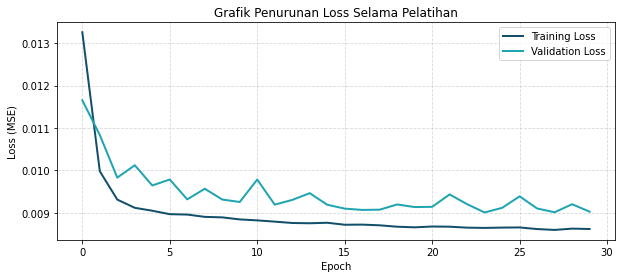

In [6]:
#202432048_NicoHaikalHafier
# 1. Plot Grafik Penurunan Loss Training terhadap Epoch
plt.figure(figsize=(10, 4))
plt.plot(train_losses, color='#114F6A', linewidth=2, label='Training Loss')
plt.plot(val_losses, color='#1FA4B1', linewidth=2, label='Validation Loss')
plt.title('Grafik Penurunan Loss Selama Pelatihan')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

MAE  : 0.3665 kW
RMSE : 0.5047 kW
R2   : 0.5187


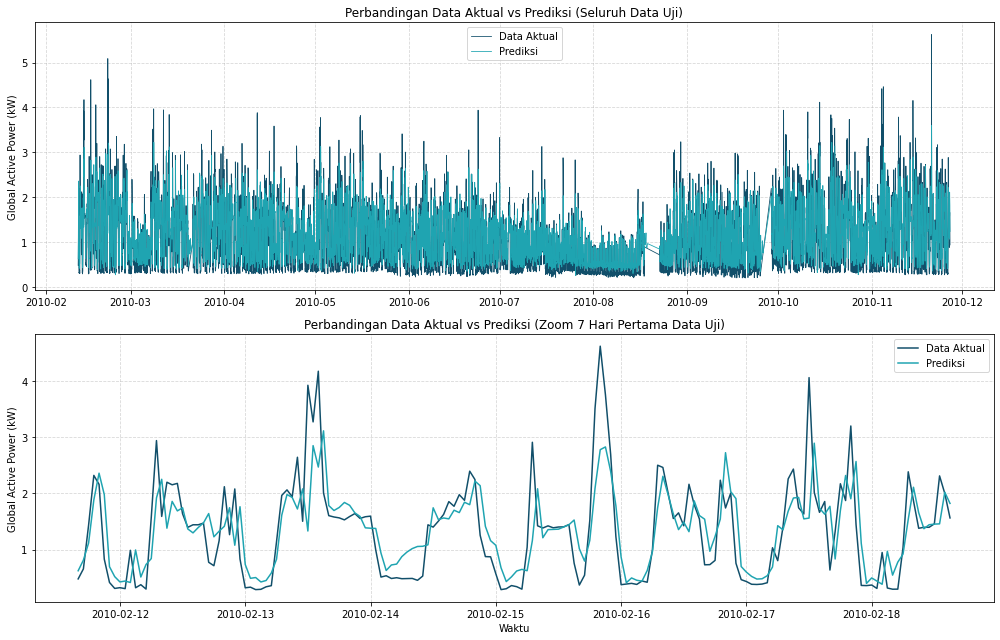

In [8]:

#202432048_NicoHaikalHafier
# 2. Prediksi pada data uji dan evaluasi

# Melakukan prediksi
model.eval()

with torch.no_grad():
    pred_scaled = model(X_test.to(device)).cpu().numpy()

# Kembalikan ke skala asli (kW)
y_pred = scaler.inverse_transform(pred_scaled).flatten()
y_true = scaler.inverse_transform(y_test.cpu().numpy()).flatten()

# Menghitung metrik evaluasi
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)

print(f'MAE  : {mae:.4f} kW')
print(f'RMSE : {rmse:.4f} kW')
print(f'R2   : {r2:.4f}')

# Plot Grafik Perbandingan Data Aktual vs Hasil Prediksi

# Konversi index Pandas menjadi NumPy
test_index = hourly.index[split_idx:].to_numpy()

n = 24 * 7  # Zoom 7 hari pertama data uji

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Grafik perbandingan seluruh data uji
axes[0].plot(
    test_index, y_true,
    color='#114F6A',
    linewidth=0.8,
    label='Data Aktual'
)

axes[0].plot(
    test_index, y_pred,
    color='#1FA4B1',
    linewidth=0.8,
    label='Prediksi'
)

axes[0].set_title(
    'Perbandingan Data Aktual vs Prediksi (Seluruh Data Uji)'
)
axes[0].set_ylabel('Global Active Power (kW)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Grafik perbandingan zoom 7 hari pertama
axes[1].plot(
    test_index[:n], y_true[:n],
    color='#114F6A',
    linewidth=1.5,
    label='Data Aktual'
)

axes[1].plot(
    test_index[:n], y_pred[:n],
    color='#1FA4B1',
    linewidth=1.5,
    label='Prediksi'
)

axes[1].set_title(
    'Perbandingan Data Aktual vs Prediksi (Zoom 7 Hari Pertama Data Uji)'
)
axes[1].set_xlabel('Waktu')
axes[1].set_ylabel('Global Active Power (kW)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

# Menampilkan grafik
plt.tight_layout()
plt.show()